In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
from clickhouse_driver import Client
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns 


client = Client(host='', port=0, user='',
                password='', database='')

def get_data(query):
    """
    Вытягивает данные из clickhouse в виде Dataframe
    
    query - запрос

    """
    result, columns = client.execute(query, with_column_types=True)
    return pd.DataFrame(result, columns=[tuple[0] for tuple in columns])


In [3]:
data = get_data(f"""
    SELECT 
        la.*, up.user_type_cars_name
    FROM hardda.live_adverts as la
    LEFT JOIN hardda.user_passports as up
        USING (passport_id)
    WHERE CAST(created_at AS date) = '2023-01-30' 
    --LIMIT 10
    """)

data.head()

,execution_date,advert_id,created_at,price,region,user_id,platform,auto_brand,auto_model,passport_id,year,userType,user_type_cars_name
0,2023-01-31,271540911,2023-01-30 00:00:17,620000,Сочи,151328585,ios,Chevrolet,Cruze,144703780,2010,0,cars_simple
1,2023-01-31,271540913,2023-01-30 00:01:21,4970000,Москва,123929189,android,Toyota,Land Cruiser,123950184,2013,6,cars_seller
2,2023-01-31,271540914,2023-01-30 00:04:42,800000,Москва,137723514,android,Subaru,Impreza,134075141,2006,0,cars_simple
3,2023-01-31,271540915,2023-01-30 00:04:57,280000,Пермь,142310446,android,Mitsubishi,RVR,137387157,1995,0,cars_simple
4,2023-01-31,271540920,2023-01-30 00:06:14,540000,Воронеж,152083420,android,Toyota,Previa,144920294,1994,0,


In [4]:
import pandas as pd 
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt




In [5]:
data['execution_date'] = pd.to_datetime(data['execution_date'])

data['user_type_cars_name'] = data['user_type_cars_name'].replace('', 'unknown')
df = data.sort_values(by='execution_date', ascending=False)\
    .groupby('advert_id')\
    .first().reset_index()

In [6]:
df['year'] = df['year'].astype(int)
df1 = df[(df['year'] != 0) & (df['price'] >= 1000)]

In [7]:
df1['log_price'] = np.log(df['price'])
df1 = df1.sort_values(by='advert_id')
print(df1.shape[0], round(df1['log_price'].mean(),3))

18021 13.303


В этом уроке мы попробуем учить модели на двух вариантах датасета: со столбцом auto_model и без него. Вместо одного X выделите из результата предыдущего шага два датафрейма:

Идея тут в том, чтобы посмотреть, как наличие или отсутствие одного признака может влиять на  качество. К тому же, это немного неоднозначный признак: он содержит более 800 уникальных значений. Вполне может прийти мысль, что это слишком много, что от такого признака будет мало толку, и можно его отбросить (тем более, учитывая, что у нас есть auto_brand). Проверим, сильно ли будет отличаться качество с этим признаком и без него. И хорошая ли это идея выбросить его из датасета.

Также подготовьте y (логарифм цены).

Разбейте данные на train/test в пропорции 80/20. Можете использовать один вызов train_test_split или два отдельных. Независимо от способа, в итоге у вас должны получиться X_train_slim, X_test_slim, X_train_full, X_test_full, y_train, y_test. Для воспроизводимости используйте random_state=42.

In [8]:
from sklearn.model_selection import train_test_split

In [9]:
X_slim = df1[['region', 'platform', 'auto_brand', 'year', 'user_type_cars_name']]
X_full = df1[['region', 'platform', 'auto_brand', 'year', 'user_type_cars_name', 'auto_model']]
y = df1['log_price']

X_train_slim, X_test_slim, y_train, y_test = train_test_split(X_slim, y
                                                              , test_size=0.2
                                                              ,random_state=42
                                                             )

X_train_full, X_test_full, y_train, y_test = train_test_split(X_full, y
                                                              , test_size=0.2
                                                              ,random_state=42
                                                             )



ColumnTransformer

Так же, как делали в других уроках, подготовим ColumnTransformer для категориальных столбцов:

Для столбцов, содержащих не более 5 уникальных значений, используйте OneHotEncoder с параметрами handle_unknown='ignore' и sparse_output=False. Устанавливать drop='first' не нужно (этот параметр полезен для линейных моделей и не очень нужен тут).
Для столбцов с более 5 уникальных категорий используйте TargetEncoder с параметрами target_type='continuous' и random_state=42.
Сделайте так, чтобы при применении трансформера остальные (не категориальные) столбцы не терялись, а оставались как есть.

А вот StandardScaler добавлять не будем. Моделям на основе деревьев масштабирование не очень важно.

Давайте сверимся. Примените написанный ColumnTransformer к данным X_train_full (дальше мы будем использовать трансформер как один из шагов пайплайна, но тут просто посмотрим, как он работает сам по себе).

В поле ниже введите три первых значения преобразованного столбца auto_model, округлённые до 2 знаков. Например, 11.12, 13.14, 15.16.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, TargetEncoder



In [11]:
cat_cols = X_train_full.select_dtypes(exclude='number').columns.tolist()
low_nunique_values = [col for col in cat_cols if X_train_full[col].nunique() <= 5]
high_nunique_values = [col for col in cat_cols if X_train_full[col].nunique() > 5]

preprocc = ColumnTransformer(transformers=[
    ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False), low_nunique_values)
    , ('te', TargetEncoder(target_type='continuous', random_state=42), high_nunique_values)
]
                             , remainder='passthrough')

k = preprocc.fit_transform(X_train_full, y_train)
cols = preprocc.get_feature_names_out()
kk = pd.DataFrame(k, columns=cols)
kk['te__auto_model'][:3].apply(lambda x: round(x, 2) )

0    12.16
1    12.19
2    14.12
Name: te__auto_model, dtype: float64

### Задача 2.

Метрики и кросс-валидация
Чтобы было удобнее сравнивать модели, будем использовать те же метрики, которые были для KNN. Непосредственно оптимизировать будем R2, но периодически будем поглядывать и на MAE.

Как обсуждали до этого, мы не будем трогать тестовую выборку до самого конца, а качество моделей будем сравнивать на кросс-валидации.

# Наивная модель


In [12]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.model_selection import cross_validate, GridSearchCV

In [13]:
base_model = DummyRegressor(strategy='mean')
cv_base_r2 = cross_validate(base_model,
                        X_train_full, 
                        y_train,
                        cv=5, scoring='r2',
                        return_train_score=True)

cv_base_MAE = cross_validate(base_model,
                        X_train_full, 
                        y_train,
                        cv=5, scoring='neg_mean_absolute_error',
                        return_train_score=True)

print('R2')
print(f"train = {cv_base_r2['train_score'].mean():.2f}, test = {cv_base_r2['test_score'].mean():.2f}")
print('MAE')
print(f"train = {-cv_base_MAE['train_score'].mean():.2f}, test = {-cv_base_MAE['test_score'].mean():.2f}")

R2
train = 0.00, test = -0.00
MAE
train = 0.90, test = 0.90


### Задача 3. Дерево решений

Начнём с самой простой из "деревянных" моделей: одиночного дерева.

Создайте пайплайн, состоящий из:

Написанного на одном из предыдущих шагов ColumnTransformer.
DecisionTreeRegressor с параметром random_state=42 (остальные параметры пока оставьте по умолчанию).
Посмотрите в документации sklearn, какие у дерева гиперпараметры по умолчанию. Т.е. каким будет дерево, если не задать гиперпараметры. Отдельно обратите внимание на max_depth и min_samples_split.

Учитывая эти значения, вы ожидаете, что дерево будет простым или наоборот слишком сложным и переобучится?

Проверьте результат на кросс-валидации. Используйте cross_validate с параметром return_train_score=True.

В качестве данных пока возьмите slim-версию, без столбца auto_model. Метрика — r2.

Как можно интерпретировать полученные результаты?

Через запятую и пробел введите значение метрики на трейне (среднее train_score) и на валидации (test_score, тоже усреднённое всем по фолдам).
Округлите значения до 2 знаков после точки. Пример: 0.71, 0.64.

In [14]:
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor

In [15]:
cat_cols_slim = X_train_slim.select_dtypes(exclude='number').columns.tolist()

low_nunique_values_slim = [col for col in cat_cols_slim if X_train_slim[col].nunique() <= 5]
high_nunique_values_slim = [col for col in cat_cols_slim if X_train_slim[col].nunique() > 5]

preprocc_slim = ColumnTransformer(transformers=[
    ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False), low_nunique_values_slim)
    , ('te', TargetEncoder(target_type='continuous', random_state=42), high_nunique_values_slim)
]
        , remainder='passthrough')

slim = preprocc_slim.fit_transform(X_train_slim, y_train)

model = Pipeline(steps=[
    ('prepare', preprocc_slim),
    ('trees1', DecisionTreeRegressor(random_state=42))
])


cv_model_slim = cross_validate(model, 
                         X_train_slim, y_train
                          , scoring='r2',
                         return_train_score=True)



In [16]:
round(cv_model_slim['train_score'].mean(),2), round(cv_model_slim['test_score'].mean(),2)

(0.65, 0.49)

Качество и на трейне не очень высокое, но на валидации намного ниже. Модель переобучилась

Будем использовать тот же пайплайн, но подберём пару гиперпараметров с помощью GridSearchCV:

Максимальная глубина дерева, значения 5, 10, 15, 20.
min_samples_split, значения 10, 20, 50, 100 (вспомните, за что конкретно отвечает этот гиперпараметр).

Оба гиперпараметра помогут сделать модель в той или иной степени более простой, по сравнению с дефолтными значениями (убедитесь, что понимаете, почему).

Как и на прошлом степе, используйте slim-версию данных, scoring='r2' и return_train_score=True, только теперь в GridSearchCV, а не в cross_validate.

Помимо найденных гиперпараметров и лучшего значения метрики, можно вывести значения метрики для разных комбинаций гиперпараметров, которые пробовал grid search. Это можно сделать, обратившись к .cv_results_.


Посмотрите на получившуюся таблицу. Какие выводы мы можем сделать?

В поле ниже через запятую и пробел введите три значения из результата grid search:

max_depth
min_samples_split
Значение метрики r2 (mean_test_score), округлённое до сотых.
Например, 20, 100, 0.65.

In [17]:
model.get_params().keys()

dict_keys(['memory', 'steps', 'verbose', 'prepare', 'trees1', 'prepare__n_jobs', 'prepare__remainder', 'prepare__sparse_threshold', 'prepare__transformer_weights', 'prepare__transformers', 'prepare__verbose', 'prepare__verbose_feature_names_out', 'prepare__ohe', 'prepare__te', 'prepare__ohe__categories', 'prepare__ohe__drop', 'prepare__ohe__dtype', 'prepare__ohe__feature_name_combiner', 'prepare__ohe__handle_unknown', 'prepare__ohe__max_categories', 'prepare__ohe__min_frequency', 'prepare__ohe__sparse', 'prepare__ohe__sparse_output', 'prepare__te__categories', 'prepare__te__cv', 'prepare__te__random_state', 'prepare__te__shuffle', 'prepare__te__smooth', 'prepare__te__target_type', 'trees1__ccp_alpha', 'trees1__criterion', 'trees1__max_depth', 'trees1__max_features', 'trees1__max_leaf_nodes', 'trees1__min_impurity_decrease', 'trees1__min_samples_leaf', 'trees1__min_samples_split', 'trees1__min_weight_fraction_leaf', 'trees1__random_state', 'trees1__splitter'])

In [18]:
param_grid = {
    'trees1__max_depth': [5, 10, 15, 20],
    'trees1__min_samples_split': [10, 20, 50, 100]
}

GS_model = GridSearchCV(model, param_grid=param_grid,
                       scoring='r2', return_train_score=True)


GS_model.fit(X_train_slim, y_train)

GridSearchCV(estimator=Pipeline(steps=[('prepare',
                                        ColumnTransformer(remainder='passthrough',
                                                          transformers=[('ohe',
                                                                         OneHotEncoder(handle_unknown='ignore',
                                                                                       sparse_output=False),
                                                                         ['platform',
                                                                          'user_type_cars_name']),
                                                                        ('te',
                                                                         TargetEncoder(random_state=42,
                                                                                       target_type='continuous'),
                                                                         ['region',
                                                                          'auto_brand'])])),
                                       ('trees1',
                                        DecisionTreeRegressor(random_state=42))]),
             param_grid={'trees1__max_depth': [5, 10, 15, 20],
                         'trees1__min_samples_split': [10, 20, 50, 100]},
             return_train_score=True, scoring='r2')

In [19]:
cols = [
    'param_trees1__max_depth',
    'param_trees1__min_samples_split',
    'mean_test_score',
    'mean_train_score',
]

pd.DataFrame(GS_model.cv_results_).sort_values('rank_test_score')[cols].reset_index(drop=True)[:3]

,param_trees1__max_depth,param_trees1__min_samples_split,mean_test_score,mean_train_score
0,10,50,0.689496,0.731236
1,10,100,0.685995,0.716129
2,15,100,0.683993,0.716703


Ответ: 10, 50, 0.69

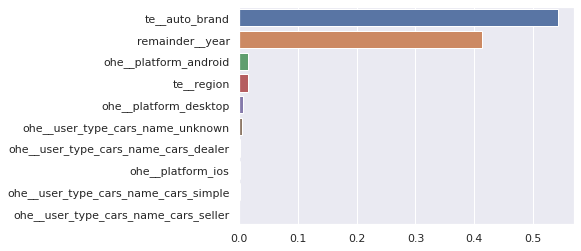

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()

def plot_feature_importances(feature_names, model, count=10):
    feature_importances = model.feature_importances_

    sorted_indices = feature_importances.argsort()[::-1]
    sorted_feature_importances = feature_importances[sorted_indices][:count]
    sorted_feature_names = feature_names[sorted_indices][:count]

    sns.barplot(x=sorted_feature_importances, y=sorted_feature_names)
    plt.show()
    
    
plot_feature_importances(
    GS_model.best_estimator_['prepare'].get_feature_names_out(),
    GS_model.best_estimator_['trees1']
)

Посмотрим, что изменится, если мы обучимся на full-версии датасета (со столбцом auto_model).

Повторим всё, что мы уже делали, но уже на этой версии датасета.

Сначала проверьте через cross_validate, какое значение R2 даст дерево с гиперпараметрами по умолчанию.

Помог ли дополнительный признак существенно улучшить качество или дерево с параметрами по умолчанию всё равно справляется плохо?

С помощью GridSearchCV подберём гиперпараметры. Используйте ту же сетку гиперпараметров, что и раньше.

Как вы можете интерпретировать полученные результаты?

В поле ниже через запятую и пробел введите два числа: R2 для дерева с параметрами по умолчанию и R2 для дерева с настроенными гиперпараметрами. Округлите значения до сотых. Например, 0.63, 0.68. Значения метрики на трейне вводить не нужно.

In [21]:
model_full = Pipeline(steps=[
    ('prepare', preprocc),
    ('trees1', DecisionTreeRegressor(random_state=42))
])


cv_model = cross_validate(model_full, 
                         X_train_full, y_train
                          , scoring='r2',
                         return_train_score=True)
print(f"Значения на slim: {round(cv_model_slim['train_score'].mean(),2), round(cv_model_slim['test_score'].mean(),2)}")
print(f"Значения на full: {round(cv_model['train_score'].mean(),2), round(cv_model['test_score'].mean(),2)}")

Значения на slim: (0.65, 0.49)
Значения на full: (0.7, 0.54)


In [22]:
grid_model = GridSearchCV(model_full, param_grid=param_grid
                         , scoring='r2', return_train_score=True)

grid_model.fit(X_train_full, y_train)

GridSearchCV(estimator=Pipeline(steps=[('prepare',
                                        ColumnTransformer(remainder='passthrough',
                                                          transformers=[('ohe',
                                                                         OneHotEncoder(handle_unknown='ignore',
                                                                                       sparse_output=False),
                                                                         ['platform',
                                                                          'user_type_cars_name']),
                                                                        ('te',
                                                                         TargetEncoder(random_state=42,
                                                                                       target_type='continuous'),
                                                                         ['region',
                                                                          'auto_brand',
                                                                          'auto_model'])])),
                                       ('trees1',
                                        DecisionTreeRegressor(random_state=42))]),
             param_grid={'trees1__max_depth': [5, 10, 15, 20],
                         'trees1__min_samples_split': [10, 20, 50, 100]},
             return_train_score=True, scoring='r2')

In [23]:
print("--- ТОП-3 на SLIM ---")
display(pd.DataFrame(grid_model.cv_results_).sort_values('rank_test_score')[cols].head(3).reset_index(drop=True))

print("--- ТОП-3 на FULL ---")
display(pd.DataFrame(GS_model.cv_results_).sort_values('rank_test_score')[cols].head(3).reset_index(drop=True))

--- ТОП-3 на SLIM ---


,param_trees1__max_depth,param_trees1__min_samples_split,mean_test_score,mean_train_score
0,10,50,0.713729,0.762126
1,10,20,0.713635,0.767425
2,15,50,0.711136,0.762632


--- ТОП-3 на FULL ---


,param_trees1__max_depth,param_trees1__min_samples_split,mean_test_score,mean_train_score
0,10,50,0.689496,0.731236
1,10,100,0.685995,0.716129
2,15,100,0.683993,0.716703


In [24]:
cv_model['test_score'].mean()

0.5433371177433839

In [25]:
grid_model.best_score_

0.7137288739694568

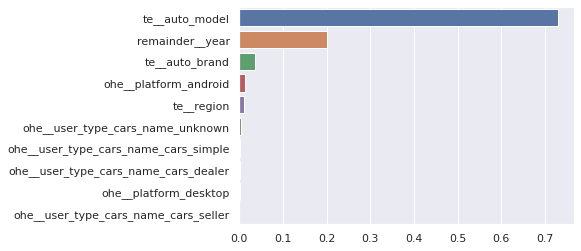

In [26]:
plot_feature_importances(
    grid_model.best_estimator_['prepare'].get_feature_names_out(),
    grid_model.best_estimator_['trees1']
)

## Задача 4. Случайный лес

Так же, как мы делали для дерева, создайте пайплайн состоящий из 2 шагов: трансформера категориальных признаков и, собственно, леса. Проверьте, какой получится R2 с гиперпараметрами по умолчанию на данных без auto_model.



In [27]:
from sklearn.ensemble import RandomForestRegressor

In [28]:
pipe_for_rf = Pipeline(steps=[
    ('preprocc_rf', preprocc_slim),
    ('forest', RandomForestRegressor(random_state=42))
])


cross_val_rf = cross_validate(pipe_for_rf
                             , X_train_slim, y_train
                             , scoring='r2'
                             , return_train_score=True)

cross_val_rf

{'fit_time': array([2.91830564, 2.91890335, 2.88686252, 2.80642176, 2.85377812]),
 'score_time': array([0.07499266, 0.07707119, 0.07844472, 0.07877755, 0.07505322]),
 'test_score': array([0.67885579, 0.66669293, 0.71881454, 0.68057565, 0.72731289]),
 'train_score': array([0.78485531, 0.80426153, 0.78673636, 0.76576288, 0.78997654])}

In [29]:
print(f"Значения на slim: {round(cv_model_slim['train_score'].mean(),2), round(cv_model_slim['test_score'].mean(),2)}")
print(f"Значения на full: {round(cv_model['train_score'].mean(),2), round(cv_model['test_score'].mean(),2)}")
print(f"Значения на full: {round(cross_val_rf['train_score'].mean(),2), round(cross_val_rf['test_score'].mean(),2)}")

Значения на slim: (0.65, 0.49)
Значения на full: (0.7, 0.54)
Значения на full: (0.79, 0.69)


In [30]:
pipe_for_rf.get_params().keys()

dict_keys(['memory', 'steps', 'verbose', 'preprocc_rf', 'forest', 'preprocc_rf__n_jobs', 'preprocc_rf__remainder', 'preprocc_rf__sparse_threshold', 'preprocc_rf__transformer_weights', 'preprocc_rf__transformers', 'preprocc_rf__verbose', 'preprocc_rf__verbose_feature_names_out', 'preprocc_rf__ohe', 'preprocc_rf__te', 'preprocc_rf__ohe__categories', 'preprocc_rf__ohe__drop', 'preprocc_rf__ohe__dtype', 'preprocc_rf__ohe__feature_name_combiner', 'preprocc_rf__ohe__handle_unknown', 'preprocc_rf__ohe__max_categories', 'preprocc_rf__ohe__min_frequency', 'preprocc_rf__ohe__sparse', 'preprocc_rf__ohe__sparse_output', 'preprocc_rf__te__categories', 'preprocc_rf__te__cv', 'preprocc_rf__te__random_state', 'preprocc_rf__te__shuffle', 'preprocc_rf__te__smooth', 'preprocc_rf__te__target_type', 'forest__bootstrap', 'forest__ccp_alpha', 'forest__criterion', 'forest__max_depth', 'forest__max_features', 'forest__max_leaf_nodes', 'forest__max_samples', 'forest__min_impurity_decrease', 'forest__min_samples

In [31]:
param_grid_rf = {
    'forest__max_depth' :[5, 10, 15, 20],
    'forest__min_samples_split' : [10, 20, 50, 100],
    'forest__n_estimators': [100]
}


gs_for_rf = GridSearchCV(pipe_for_rf,
                        param_grid=param_grid_rf,
                        scoring='r2', 
                        return_train_score=True,
                        n_jobs=-1)

gs_for_rf.fit(X_train_slim, y_train)

GridSearchCV(estimator=Pipeline(steps=[('preprocc_rf',
                                        ColumnTransformer(remainder='passthrough',
                                                          transformers=[('ohe',
                                                                         OneHotEncoder(handle_unknown='ignore',
                                                                                       sparse_output=False),
                                                                         ['platform',
                                                                          'user_type_cars_name']),
                                                                        ('te',
                                                                         TargetEncoder(random_state=42,
                                                                                       target_type='continuous'),
                                                                         ['region',
                                                                          'auto_brand'])])),
                                       ('forest',
                                        RandomForestRegressor(random_state=42))]),
             n_jobs=-1,
             param_grid={'forest__max_depth': [5, 10, 15, 20],
                         'forest__min_samples_split': [10, 20, 50, 100],
                         'forest__n_estimators': [100]},
             return_train_score=True, scoring='r2')

In [32]:
gs_for_rf.best_params_

{'forest__max_depth': 10,
 'forest__min_samples_split': 10,
 'forest__n_estimators': 100}

In [33]:
gs_for_rf.best_score_

0.7202236045290438

С помощью cross_validate оцените качество для леса с гиперпараметрами по умолчанию, но обученного на full-данных, со столбцом auto_model.

In [34]:
pipe_for_rf2 = Pipeline(steps=[
    ('preprocc_rf', preprocc),
    ('forest', RandomForestRegressor(random_state=42))
])


cross_val_rf_slim = cross_validate(pipe_for_rf2
                             , X_train_full, y_train
                             , scoring='r2'
                             , return_train_score=True)

cross_val_rf_slim['test_score'].mean()

0.74600715395348

Подберите гиперпараметры, используя ту же сетку, что на предыдущем шаге.

На следующем шаге мы перейдём к другой модели. Зафиксируйте для себя, какого качества нам удалось добиться с помощью случайного леса.

В поле ниже через запятую и пробел введите четыре значения, полученные на этом шаге:

Значение r2 для леса с гиперпараметрами по умолчанию (округлите до 2 знаков).
Подобранная max_depth.
Подобранный min_samples_split.
Значение r2 для леса с настроенными гиперпараметрами (округлите до 2 знаков).
Например, 0.65, 20, 100, 0.68.



In [35]:
param_grid_rf = {
    'forest__max_depth' :[5, 10, 15, 20],
    'forest__min_samples_split' : [10, 20, 50, 100],
    'forest__n_estimators': [100]
}

grid_rf_full = GridSearchCV(pipe_for_rf2,
                            param_grid=param_grid_rf, 
                            scoring='r2', 
                            return_train_score=True,
                            n_jobs=-1)

grid_rf_full.fit(X_train_full, y_train)

GridSearchCV(estimator=Pipeline(steps=[('preprocc_rf',
                                        ColumnTransformer(remainder='passthrough',
                                                          transformers=[('ohe',
                                                                         OneHotEncoder(handle_unknown='ignore',
                                                                                       sparse_output=False),
                                                                         ['platform',
                                                                          'user_type_cars_name']),
                                                                        ('te',
                                                                         TargetEncoder(random_state=42,
                                                                                       target_type='continuous'),
                                                                         ['region',
                                                                          'auto_brand',
                                                                          'auto_model'])])),
                                       ('forest',
                                        RandomForestRegressor(random_state=42))]),
             n_jobs=-1,
             param_grid={'forest__max_depth': [5, 10, 15, 20],
                         'forest__min_samples_split': [10, 20, 50, 100],
                         'forest__n_estimators': [100]},
             return_train_score=True, scoring='r2')

In [36]:
print(grid_rf_full.best_params_)
print(round(grid_rf_full.best_score_,2))

{'forest__max_depth': 15, 'forest__min_samples_split': 10, 'forest__n_estimators': 100}
0.76


### Задача 5. XGBoost

In [38]:
from xgboost import XGBRegressor

In [41]:
pipeline_XGB = Pipeline(steps=[
    ('preprocc_XGB', preprocc),
    ('XGB', XGBRegressor(random_state=42, n_jobs=1, seed=0))
])

XGB_cv = cross_validate(pipeline_XGB
                        , X_train_full, y_train
                        , return_train_score=True
                        , scoring='r2')

XGB_cv['test_score'].mean()

0.7484984860827392

In [42]:
pipeline_XGB.get_params().keys()

dict_keys(['memory', 'steps', 'verbose', 'preprocc_XGB', 'XGB', 'preprocc_XGB__n_jobs', 'preprocc_XGB__remainder', 'preprocc_XGB__sparse_threshold', 'preprocc_XGB__transformer_weights', 'preprocc_XGB__transformers', 'preprocc_XGB__verbose', 'preprocc_XGB__verbose_feature_names_out', 'preprocc_XGB__ohe', 'preprocc_XGB__te', 'preprocc_XGB__ohe__categories', 'preprocc_XGB__ohe__drop', 'preprocc_XGB__ohe__dtype', 'preprocc_XGB__ohe__feature_name_combiner', 'preprocc_XGB__ohe__handle_unknown', 'preprocc_XGB__ohe__max_categories', 'preprocc_XGB__ohe__min_frequency', 'preprocc_XGB__ohe__sparse', 'preprocc_XGB__ohe__sparse_output', 'preprocc_XGB__te__categories', 'preprocc_XGB__te__cv', 'preprocc_XGB__te__random_state', 'preprocc_XGB__te__shuffle', 'preprocc_XGB__te__smooth', 'preprocc_XGB__te__target_type', 'XGB__objective', 'XGB__base_score', 'XGB__booster', 'XGB__callbacks', 'XGB__colsample_bylevel', 'XGB__colsample_bynode', 'XGB__colsample_bytree', 'XGB__device', 'XGB__early_stopping_round

In [43]:
param_XGB = {
    'XGB__max_depth':[3, 4, 5, 6, 7, 8],
    'XGB__n_estimators':[20, 30, 40, 50]
}

XGB_gs = GridSearchCV(pipeline_XGB, param_grid=param_XGB
                     , scoring='r2', return_train_score=True
                     , n_jobs=-1)

XGB_gs.fit(X_train_full, y_train)

GridSearchCV(estimator=Pipeline(steps=[('preprocc_XGB',
                                        ColumnTransformer(remainder='passthrough',
                                                          transformers=[('ohe',
                                                                         OneHotEncoder(handle_unknown='ignore',
                                                                                       sparse_output=False),
                                                                         ['platform',
                                                                          'user_type_cars_name']),
                                                                        ('te',
                                                                         TargetEncoder(random_state=42,
                                                                                       target_type='continuous'),
                                                                         ['region',
                                                                          'auto_brand',
                                                                          'auto_model'])])),
                                       ('XGB',
                                        XGBRegressor(base_score=Non...
                                                     max_cat_to_onehot=None,
                                                     max_delta_step=None,
                                                     max_depth=None,
                                                     max_leaves=None,
                                                     min_child_weight=None,
                                                     missing=nan,
                                                     monotone_constraints=None,
                                                     multi_strategy=None,
                                                     n_estimators=None,
                                                     n_jobs=1,
                                                     num_parallel_tree=None,
                                                     random_state=42, ...))]),
             n_jobs=-1,
             param_grid={'XGB__max_depth': [3, 4, 5, 6, 7, 8],
                         'XGB__n_estimators': [20, 30, 40, 50]},
             return_train_score=True, scoring='r2')

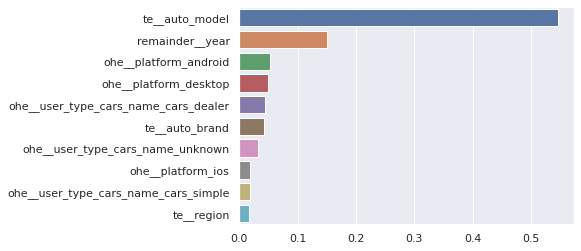

In [46]:
plot_feature_importances(
    XGB_gs.best_estimator_['preprocc_XGB'].get_feature_names_out(),
    XGB_gs.best_estimator_['XGB']
)

In [47]:
XGB_gs.best_params_, XGB_gs.best_score_

({'XGB__max_depth': 7, 'XGB__n_estimators': 30}, 0.757063616083564)

In [49]:
print(f"Значение r2 для xgboost с гиперпараметрами по умолчанию - {round(XGB_cv['test_score'].mean(),2)}")
print(f"Подобранная max_depth. Подобранное значение n_estimators : {XGB_gs.best_params_}")
print(f"Значение r2 для xgboost с настроенными гиперпараметрами : {round(XGB_gs.best_score_,2)}")

Значение r2 для xgboost с гиперпараметрами по умолчанию - 0.75
Подобранная max_depth. Подобранное значение n_estimators : {'XGB__max_depth': 7, 'XGB__n_estimators': 30}
Значение r2 для xgboost с настроенными гиперпараметрами : 0.76


### Задача 6. CatBoost 

Как и до этого, создайте пайплайн, состоящий из трансформера для категорий и самой модели — CatBoostRegressor с параметрами random_state=42, verbose=False.

In [50]:
from catboost import CatBoostRegressor

In [53]:
pipe_cb_slim = Pipeline(steps=[
    ('preprocc_cb_slim', preprocc_slim),
    ('CB_model_slim', CatBoostRegressor(random_state=42, verbose=False))
])

cv_cb_slim = cross_validate(pipe_cb_slim
                           , X_train_slim
                           , y_train
                           , scoring='r2'
                           , return_train_score=True)

print(f"Кросс-Вал на slim-данных: {round(cv_cb_slim['test_score'].mean(),3)}")

Кросс-Вал на slim-данных: 0.72


In [58]:
pipe_cb_full = Pipeline(steps=[
    ('preprocc_cb_full', preprocc),
    ('CB_model_full', CatBoostRegressor(random_state=42, verbose=False))
])

cv_cb_full = cross_validate(pipe_cb_full
                           , X_train_full
                           , y_train
                           , scoring='r2'
                           , return_train_score=True)

print(f"Кросс-Вал на full-данных: {round(cv_cb_full['test_score'].mean(),3)}")

Кросс-Вал на full-данных: 0.762


Сначала на slim-версии данных без auto_model.

Создайте CatBoostRegressor с параметрами cat_features=['region', 'platform', 'auto_brand', 'user_type_cars_name'], random_state=42, verbose=False.

Не создавая никаких пайплайнов, не настраивая гиперпараметры, используйте непосредственно эту модель в cross_validate для получения r2 на кросс-валидации.

Что можно сказать о результатах?

In [59]:
cb_model_slim = CatBoostRegressor(
    cat_features=['region', 'platform', 'auto_brand', 'user_type_cars_name'], random_state=42, verbose=False
)

cv_cb_slim2 = cross_validate(cb_model_slim
                             , X_train_slim
                             , y_train
                             , scoring='r2'
                             , return_train_score=True
                            )

round(cv_cb_slim2['test_score'].mean(), 2)

0.74

Попробуем то же самое на полных данных, с признаком auto_model.

Дополните cat_features и проверьте качество на кросс-валидации на полных данных (так же, не создавая пайплайнов и не настраивая гиперпараметры).

Посмотрите получившиеся важности признаков. Т.к. тут не было grid search, который сделал бы это за нас, сначала обучите модель на соответствующей обучающей выборке. А в качестве названий столбцов, используемых при отрисовке графика, можно взять просто названия столбцов датасета, X_full.columns.

Через запятую и пробел введите два значения r2, полученные на этом шаге (на двух вариантах данных). Округлите до 2 знаков. Например, 0.65, 0.68.

In [61]:
cb_model_full = CatBoostRegressor(
    cat_features=['region', 'platform', 'auto_brand', 'user_type_cars_name', 'auto_model'], random_state=42, verbose=False
)

cv_cb_full2 = cross_validate(cb_model_full
                             , X_train_full
                             , y_train
                             , scoring='r2'
                             , return_train_score=True
                            )

round(cv_cb_full2['test_score'].mean(), 2)

0.77

Заново обучите на обучающих данных две эти две модели. Если мы подбирали гиперпараметры для них, используйте лучшую комбинацию гиперпараметров.

Для каждой из них измерьте R2 и MAE на соответствующих тестовых выборках, созданных в начале урока.

Получилось ли качество на тесте таким же, как на кросс-валидации?

Сравните полученные результаты с тем, что у нас получилось в задании по KNN.

В поле ниже через запятую и пробел введите четыре значения, полученные на тестовой выборке:

Значение R2 для slim-данных.

Значение MAE для slim-данных.

Значение R2 для full-данных.

Значение MAE для full-данных.

Все значения округлите до 2 знаков. Например, 0.65, 0.43, 0.68, 0.41.



In [66]:
cb_model_full.fit(X_train_full, y_train)

y_pred_full = cb_model_full.predict(X_test_full)

r2_full = r2_score(y_test, y_pred_full)
mae_full = mean_absolute_error(y_test, y_pred_full)
print(f"R2 full: {r2_full:.2f}, MAE full: {mae_full:.2f}")


R2 full: 0.77, MAE full: 0.34


In [68]:
cb_model_slim.fit(X_train_slim, y_train)

y_pred_slim = cb_model_slim.predict(X_test_slim)

r2_slim = r2_score(y_test, y_pred_slim)
mae_slim = mean_absolute_error(y_test, y_pred_slim)
print(f"R2 slim: {r2_slim:.2f}, MAE slim: {mae_slim:.2f}")

R2 slim: 0.74, MAE slim: 0.37
